In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

%matplotlib inline


In [5]:
# submit the run.
batch_script = '''\
#!/bin/bash
#SBATCH --job-name={job_name}
#SBATCH --partition=cpu
#SBATCH -N 1
#SBATCH --ntasks-per-node=1
#SBATCH --cpus-per-task=5
#SBATCH --mem=10G
#SBATCH --mail-type=end
#SBATCH --mail-user=YOU@EMAIL.COM
#SBATCH --output=out/%j.out
#SBATCH --error=out/%j.err
{cmd}
'''
pre = "/home/luw//DMS/jun07/"
pdbDir = "/home/luw//DMS/jun07/BindingGYM/"
os.system(f"mkdir -p {pre}/out/")
os.system(f"mkdir -p {pre}/slurm_scripts/")
os.system(f"mkdir -p {pre}/logs/")
os.system(f"cp {pre}/may/rotabase.txt {pre}")

0

In [6]:
# os.system(f"rm -r {pre}/out")
# os.system(f"rm -r {pre}/foldx_results")
# os.system(f"rm -r {pre}/slurm_scripts")

In [7]:
def run_script_on_server(pre, pdbFile, mut_individual_list_file, outFileFolder, scriptFileName, logFile, pdbDir=pdbDir):
    foldx = "/home/luw//packages/foldx/foldx"
    # pdbFile = "3GBN_hm.pdb"
    # mutantFile = "individual_list.txt"
    # only one space is allowed.
    cmd = f"{foldx} --command=BuildModel --pdb={pdbFile} --mutant-file={mut_individual_list_file} --output-dir={outFileFolder} --pdb-dir={pdbDir} > {logFile}\n"
    line = batch_script.format(job_name=f'batch_{i}',
                                  cmd=cmd,)
    with open(scriptFileName, "w") as out:
        out.write(line+"\n")
    return cmd

def get_mutantFile_cmd(data, mapping=None):
    mutantFile_cmd = []
    for i, line in data.iterrows():
        mutant_pdb = eval(line['mutant_pdb'])
        mut_list = []
        for mut_chain in mutant_pdb.keys():
            muts = mutant_pdb[mut_chain]
            for m in muts.split(":"):
                if len(m) == 0:
                    continue
                mut_from_res = m[0]
                mut_to_res = m[-1]
                mut_resid = (m[1:-1]).upper()
                if mapping is not None:
                    mut_resid = mapping[mut_chain+"_"+mut_resid]
                else:
                    if not mut_resid.isnumeric():
                        # print("check", m, mut_resid)
                        raise
                        mut_resid = mut_resid[:-1]
                    assert mut_resid.isnumeric()
                mut_list.append(f"{mut_from_res}{mut_chain}{mut_resid}{mut_to_res}")
        mutantFile_cmd.append(",".join(mut_list))
    return mutantFile_cmd

def mutation_to_itself(mut):
    x = list(mut)
    x[-1] = x[0]
    return "".join(x)



In [8]:
from Bio import PDB

def renumber_residues(input_file, output_file):
    parser = PDB.PDBParser(QUIET=True)
    original_structure = parser.get_structure('PDB', input_file)

    # Create a new structure
    new_structure = PDB.Structure.Structure('NEW')
    
    residue_id_map = {}  # Dictionary to store mapping from old to new IDs

    for model in original_structure:
        new_model = PDB.Model.Model(model.id)
        new_structure.add(new_model)
        for chain in model:
            new_chain = PDB.Chain.Chain(chain.id)
            new_model.add(new_chain)
            residue_number = 1
            for residue in chain.get_residues():
                if PDB.is_aa(residue, standard=True):
                    old_id = residue.id
                    new_id = (' ', residue_number, ' ')  # Reset the insertion code

                    # Create a new residue with the new ID
                    new_residue = PDB.Residue.Residue(new_id, residue.resname, residue.segid)
                    
                    # Copy all atoms from the original residue to the new residue
                    for atom in residue:
                        new_atom = PDB.Atom.Atom(atom.name, atom.coord, atom.bfactor, atom.occupancy, atom.altloc,
                                                 atom.fullname, atom.serial_number, element=atom.element)
                        new_residue.add(new_atom)

                    new_chain.add(new_residue)
                    uid = chain.id + "_" + (str(old_id[1]) if old_id[2] == ' ' else str(old_id[1]) + old_id[2])
                    residue_id_map[uid] = str(residue_number)
                    residue_number += 1

    # Save the modified structure
    io = PDB.PDBIO()
    io.set_structure(new_structure)
    io.save(output_file)

    return residue_id_map




In [9]:
import glob
from tqdm import tqdm
fileList = glob.glob("/home/luw//DMS/jun07/Binding_substitutions_DMS/*.csv")


In [10]:
run_list = []
# fileList = ['/home/luw//DMS/Binding_substitutions_DMS/Z-domain_ZSPA-1_LL1_fitness_1LP1.csv']
# fileList = ['/home/luw//DMS/Binding_substitutions_DMS/4D5_HER2_fitness_1N8Z_v2.csv']
for _, fileName in enumerate(tqdm(fileList)):
    entryName = os.path.basename(fileName)[:-4]
    data = pd.read_csv(fileName)
    raw_pdb_file = os.path.join(pdbDir, 
                                data['pdb_file'].iloc[0])
    pdb_file = raw_pdb_file.replace(".pdb", "_renumbered.pdb")
    mapping = renumber_residues(raw_pdb_file, pdb_file)
    
    mutantFile_cmd = get_mutantFile_cmd(data, mapping=mapping)
    data['foldx_mut'] = mutantFile_cmd
    one_mut = data.query("foldx_mut != ''").iloc[0]['foldx_mut']
    data['foldx_mut'] = data['foldx_mut'].apply(lambda x: mutation_to_itself(one_mut) if x=='' else x)

    n = len(data)
    n_per_batch = 1000
    batch_n = ((n - 1) // n_per_batch) + 1
    for i in range(batch_n):
        batch_pre = f"{pre}/foldx_results/dataset_{entryName}/batch_{i}"
        outFileFolder = f"{batch_pre}/"
        os.system(f"mkdir -p {outFileFolder}")
        logFile = f"{pre}/logs/dataset_{entryName}_batch_{i}.log"
        d = data.iloc[i*n_per_batch:(i+1)*n_per_batch].reset_index(drop=True)
        mutantFile_cmd = ";\n".join(d['foldx_mut']) + ";"
        mut_individual_list_file = f"{batch_pre}/individual_list.txt"
        with open(mut_individual_list_file, "w") as f:
            f.write(mutantFile_cmd)

        scriptFileName = f"{pre}/slurm_scripts/{entryName}_{i}.slurm"
        run_script_on_server(pre, os.path.basename(pdb_file), mut_individual_list_file, outFileFolder, scriptFileName, logFile)
        run_list.append(f"{entryName}_{i}")


100%|██████████| 28/28 [00:44<00:00,  1.57s/it]


In [14]:
len(run_list)

522

In [15]:
run_list[0]

'4D5_HER2_fitness_1N8Z_0'

In [13]:
with open(f"{pre}/run.sh", "w") as f:
    for run in run_list[1:]:
        f.write(f"sbatch slurm_scripts/{run}.slurm\n")

In [16]:
d_dict = {}
for _, fileName in enumerate(tqdm(fileList)):
    d_list = []
    entryName = os.path.basename(fileName)[:-4]
    data = pd.read_csv(fileName)
    pdb = data['pdb_file'].iloc[0].replace(".pdb", "_renumbered")
    n = len(data)
    n_per_batch = 1000
    batch_n = ((n - 1) // n_per_batch) + 1
    for i in range(batch_n):
        batch_pre = f"{pre}/foldx_results/dataset_{entryName}/batch_{i}"
        foldx = pd.read_csv(f"{batch_pre}/Average_{pdb}.fxout", sep='\t', skiprows=8)
        d = data.iloc[i*n_per_batch:(i+1)*n_per_batch].reset_index(drop=True)
        if len(foldx) != len(d):
            print("not yet complete", entryName, i, len(foldx), len(d))
        d = d.iloc[:len(foldx)].reset_index(drop=True)
        d['foldx'] = foldx['total energy']
        d_list.append(d)
    d = pd.concat(d_list).reset_index(drop=True)
    d_dict[entryName] = d


100%|██████████| 28/28 [00:31<00:00,  1.12s/it]


In [17]:
from scipy.stats import pearsonr, spearmanr
# pearsonr(d['DMS_score'], d['foldx_energy'])

In [22]:
import pickle

In [32]:
pickle.dump(d_dict, open(f"{pre}/foldx_results.pkl", "wb"))

In [20]:
d_dict[entryName]

,POI,DMS_score,wildtype_sequence,mutant,mutated_sequence,chain_id,pdb_file,mutant_pdb,foldx
0,1JMQ_hm,1.000000,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': '', 'P': ''}",{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,AP,1JMQ_hm.pdb,"{'A': '', 'P': ''}",-0.003488
1,1JMQ_hm,1.401235,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'D6E', 'P': ''}",{'A': 'FEIPDEVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,AP,1JMQ_hm.pdb,"{'A': 'D10E', 'P': ''}",-0.257273
2,1JMQ_hm,0.518932,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'T33S', 'P': ''}",{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTSTWQDPR...,AP,1JMQ_hm.pdb,"{'A': 'T37S', 'P': ''}",1.663060
3,1JMQ_hm,0.799915,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'T32S', 'P': ''}",{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQSTTWQDPR...,AP,1JMQ_hm.pdb,"{'A': 'T36S', 'P': ''}",-1.488580
4,1JMQ_hm,0.157850,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'R39H', 'P': ''}",{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPH...,AP,1JMQ_hm.pdb,"{'A': 'R43H', 'P': ''}",-0.013229
...,...,...,...,...,...,...,...,...,...
18402,1JMQ_hm,2.169028,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'D6V:S19R:S20T', 'P': ''}",{'A': 'FEIPDVVPLPAGWEMAKTRTGQRYFLNHIDQTTTWQDPR...,AP,1JMQ_hm.pdb,"{'A': 'D10V:S23R:S24T', 'P': ''}",-0.266831
18403,1JMQ_hm,2.351336,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'A11V:Q22H:I29R:Q36L', 'P': ''}",{'A': 'FEIPDDVPLPVGWEMAKTSSGHRYFLNHRDQTTTWLDPR...,AP,1JMQ_hm.pdb,"{'A': 'A15V:Q26H:I33R:Q40L', 'P': ''}",1.814420
18404,1JMQ_hm,0.802697,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'P8A:I29S:D30E:Q36R', 'P': ''}",{'A': 'FEIPDDVALPAGWEMAKTSSGQRYFLNHSEQTTTWRDPR...,AP,1JMQ_hm.pdb,"{'A': 'P12A:I33S:D34E:Q40R', 'P': ''}",0.107448
18405,1JMQ_hm,3.353705,{'A': 'FEIPDDVPLPAGWEMAKTSSGQRYFLNHIDQTTTWQDPR...,"{'A': 'D6V:S20Y:R23H', 'P': ''}",{'A': 'FEIPDVVPLPAGWEMAKTSYGQHYFLNHIDQTTTWQDPR...,AP,1JMQ_hm.pdb,"{'A': 'D10V:S24Y:R27H', 'P': ''}",0.110798


In [26]:
sr_list = []
for entryName in d_dict.keys():
    print(entryName, len(d_dict[entryName]))
    d = d_dict[entryName]
    print(pearsonr(d['DMS_score'], d['foldx']))
    sr_list.append(spearmanr(d['DMS_score'], d['foldx'])[0])

4D5_HER2_fitness_1N8Z 2080
PearsonRResult(statistic=-0.23543260034944277, pvalue=1.3699422976226983e-27)
5A12_Ang2_fitness_4ZFG 944
PearsonRResult(statistic=0.019795711817456974, pvalue=0.5435399387217952)
5A12_VEGF_fitness_4ZFF 29981
PearsonRResult(statistic=-0.4337112366352204, pvalue=0.0)
ACE2_SARS2-RBD_enrich_6M17 2186
PearsonRResult(statistic=-0.3261667674506604, pvalue=2.363687434542956e-55)
BH3_Bcl-xL_normed_1PQ1 518
PearsonRResult(statistic=-0.46041931194081503, pvalue=1.5309160791826971e-28)
BH3_Mcl-1_normed_3KZ0 518
PearsonRResult(statistic=-0.279591282484934, pvalue=9.316661543206651e-11)
CD19_FMC63_Fitness_7URV 3886
PearsonRResult(statistic=0.2269894129185161, pvalue=1.3621513449410931e-46)
CR6261_FluAH1_logKd_3GBN 1887
PearsonRResult(statistic=-0.7202449612748123, pvalue=1.0928813162369135e-301)
CR9114_FluAH1_logKd_4FQI 65094
PearsonRResult(statistic=-0.45237214663135633, pvalue=0.0)
CR9114_FluAH3_logKd_4FQY 65535
PearsonRResult(statistic=-0.1419413683469476, pvalue=5.1365

In [27]:
np.mean(sr_list)

-0.32932101247810186

In [61]:
for entryName in d_dict.keys():
    print(entryName, len(d_dict[entryName]))
    d = d_dict[entryName]
    print(pearsonr(d['DMS_score'], d['foldx']))

4D5_HER2_fitness_1N8Z 14350
PearsonRResult(statistic=-0.1305100222528309, pvalue=1.5168057129752369e-55)
5A12_Ang2_fitness_4ZFG 944
PearsonRResult(statistic=0.019795711817456974, pvalue=0.5435399387217952)
5A12_VEGF_fitness_4ZFF 29981
PearsonRResult(statistic=-0.4337112366352204, pvalue=0.0)
CR6261_FluAH1_logKd_3GBN 1887
PearsonRResult(statistic=-0.7202449612748123, pvalue=1.0928813162369135e-301)
CR9114_FluAH1_logKd_4FQI 65094
PearsonRResult(statistic=-0.45237214663135633, pvalue=0.0)
CR9114_FluAH3_logKd_4FQY 65535
PearsonRResult(statistic=-0.1419413683469476, pvalue=5.136502216777959e-292)
CXCR4_CXCL12_enrich_8U4O 5585
PearsonRResult(statistic=-0.1736994939020843, pvalue=4.4171050325527e-39)
Z-domain_ZSPA-1_LL1_fitness_1LP1 45215
PearsonRResult(statistic=0.04138533677539144, pvalue=1.3245902252979099e-18)
Z-domain_ZSPA-1_LL2_fitness_1LP1 25423
PearsonRResult(statistic=-0.11967985637682499, pvalue=9.606654356149176e-82)
Z-domain_ZpA963_HL1_fitness_2M5A 11130
PearsonRResult(statistic=-

In [58]:
for entryName in d_dict.keys():
    print(entryName, len(d_dict[entryName]))
    d = d_dict[entryName]
    print(pearsonr(d['DMS_score'], d['foldx']))

4D5_HER2_fitness_1N8Z_v2 81
PearsonRResult(statistic=-0.21242518303100594, pvalue=0.056922958635116455)


In [51]:
old_d_dict = d_dict

In [45]:
for entryName in d_dict.keys():
    print(entryName, len(d_dict[entryName]))
    d = d_dict[entryName]
    print(pearsonr(d['DMS_score'], d['foldx']))

4D5_HER2_fitness_1N8Z 6569
PearsonRResult(statistic=-0.06939576184101441, pvalue=1.800004346642034e-08)
5A12_Ang2_fitness_4ZFG 944
PearsonRResult(statistic=0.019795711817456974, pvalue=0.5435399387217952)
5A12_VEGF_fitness_4ZFF 25053
PearsonRResult(statistic=-0.4700310070050438, pvalue=0.0)
CR6261_FluAH1_logKd_3GBN 1231
PearsonRResult(statistic=-0.7407119007774178, pvalue=1.5248029088397517e-214)
CR9114_FluAH1_logKd_4FQI 58746
PearsonRResult(statistic=-0.44750811959574655, pvalue=0.0)
CR9114_FluAH3_logKd_4FQY 52567
PearsonRResult(statistic=-0.13903569839573932, pvalue=3.8692475965859454e-225)
CXCR4_CXCL12_enrich_8U4O 5585
PearsonRResult(statistic=-0.1736994939020843, pvalue=4.4171050325527e-39)
Z-domain_ZSPA-1_LL1_fitness_1LP1 19220
PearsonRResult(statistic=-0.0077570567861006655, pvalue=0.2822157207337611)
Z-domain_ZSPA-1_LL2_fitness_1LP1 11630
PearsonRResult(statistic=-0.10703345785603194, pvalue=5.531624116253907e-31)
Z-domain_ZpA963_HL1_fitness_2M5A 10984
PearsonRResult(statistic=-

In [37]:
foldx.columns

Index(['Pdb', 'SD', 'total energy', 'Backbone Hbond', 'Sidechain Hbond',
       'Van der Waals', 'Electrostatics', 'Solvation Polar',
       'Solvation Hydrophobic', 'Van der Waals clashes', 'entropy sidechain',
       'entropy mainchain', 'sloop_entropy', 'mloop_entropy', 'cis_bond',
       'torsional clash', 'backbone clash', 'helix dipole', 'water bridge',
       'disulfide', 'electrostatic kon', 'partial covalent bonds',
       'energy Ionisation', 'Entropy Complex'],
      dtype='object')

<Axes: >

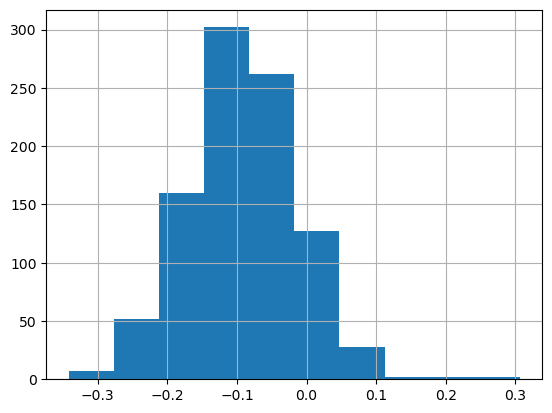

In [47]:
data = pd.read_csv('/home/luw//DMS/Binding_substitutions_DMS/5A12_Ang2_fitness_4ZFG.csv')
data['DMS_score'].hist()

In [11]:
foldx

,Pdb,SD,total energy,Backbone Hbond,Sidechain Hbond,Van der Waals,Electrostatics,Solvation Polar,Solvation Hydrophobic,Van der Waals clashes,...,cis_bond,torsional clash,backbone clash,helix dipole,water bridge,disulfide,electrostatic kon,partial covalent bonds,energy Ionisation,Entropy Complex
0,1N8Z_hm_renumbered_1,0,12.33200,0.423434,0.461502,-0.419007,-0.064126,0.470619,-0.701397,9.52573,...,0.043820,0.000631,0.280384,0,0,0.000000e+00,7.466230e-03,0,0.000000,0
1,1N8Z_hm_renumbered_2,0,9.21881,-0.652879,-0.400292,-2.369900,-0.288443,2.294990,-3.535070,9.76212,...,0.056651,0.229527,0.641561,0,0,-1.421090e-14,3.826450e-02,0,-0.137511,0
2,1N8Z_hm_renumbered_3,0,15.40330,1.589280,2.580470,-2.220130,-0.155758,-0.471388,-5.375770,14.61440,...,0.036466,0.138368,-0.771447,0,0,5.684340e-14,-1.228180e-08,0,-0.138478,0
3,1N8Z_hm_renumbered_4,0,15.98690,0.619012,2.122980,-2.454980,0.287590,-1.478180,-5.807890,18.83680,...,0.055746,0.053855,-0.742299,0,0,5.684340e-14,5.234690e-02,0,0.114485,0
4,1N8Z_hm_renumbered_5,0,13.83580,0.192333,0.396382,-3.100280,0.149159,0.385879,-5.891710,18.17090,...,0.049706,-0.002885,-0.853018,0,0,5.684340e-14,2.987070e-03,0,0.008044,0
5,1N8Z_hm_renumbered_6,0,12.44450,1.288710,4.655040,-0.096435,0.363884,-3.863950,-1.893960,9.64839,...,0.046632,-0.259783,-0.847747,0,0,5.684340e-14,-1.538080e-02,0,-0.137619,0
6,1N8Z_hm_renumbered_7,0,7.44327,-0.899527,1.903700,-1.830920,1.792300,-4.563530,-5.649700,13.02210,...,0.056675,0.239244,-0.722450,0,0,1.421090e-13,3.893880e-01,0,-0.138245,0


In [10]:
d = pd.read_csv('/home/luw//DMS/Binding_substitutions_DMS/CXCR4_CXCL12_enrich_8U4O.csv')

In [48]:
pdb = "8U4O_hm"

raw_input = pd.read_csv(f"/home/luw//DMS/foldx_results/batch_6/Raw_{pdb}.fxout", sep='\t', skiprows=8)
# group['model_foldx'] = foldx['total'].values
# raw_input = pd.read_csv(f"/home/luw//DMS/foldx_results/batch_6/{pdb}/Raw_{pdb}.fxout", sep='\s+', skiprows=8)
# wt_energy = raw_input.iloc[1::2]['energy']
# energy = raw_input.iloc[::2]['energy']

In [49]:
pd.read_csv(f"/home/luw//DMS/foldx_results/batch_6/Average_{pdb}.fxout", sep='\s+', skiprows=8)

,Pdb,SD,total,energy,Backbone,Hbond,Sidechain,Hbond.1,Van,der,...,disulfide,electrostatic,kon,partial,covalent,bonds,energy.1,Ionisation,Entropy,Complex
0,8U4O_hm_1,0,-0.023032,0.000000e+00,0.000000e+00,0.001271,6.307840e-06,-0.002047,0.001344,-4.547470e-13,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8U4O_hm_2,0,0.137633,0.000000e+00,7.105430e-15,0.529447,-1.433110e-02,-0.637938,0.784050,-2.387420e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8U4O_hm_3,0,0.153876,2.842170e-14,-2.712150e-01,0.526855,-1.117790e-01,-0.539314,0.792272,3.815070e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8U4O_hm_4,0,0.131477,5.684340e-14,2.842170e-14,0.773265,-2.177560e-01,-0.766175,1.128900,1.293190e-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8U4O_hm_5,0,0.060901,-1.716980e+00,-1.679480e+00,-0.283413,-5.763930e-02,1.852960,-0.003317,7.747230e-04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5580,8U4O_hm_5581,0,-1.038520,-1.008280e+00,-7.221850e-01,-0.338370,-1.776360e-15,0.617014,-0.378717,3.761890e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5581,8U4O_hm_5582,0,-0.130907,0.000000e+00,0.000000e+00,-0.005430,0.000000e+00,-0.156377,0.017262,0.000000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5582,8U4O_hm_5583,0,0.055039,-1.800790e-02,0.000000e+00,-0.221643,0.000000e+00,0.440282,-0.299863,0.000000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5583,8U4O_hm_5584,0,-0.594319,1.619880e-02,0.000000e+00,-0.460759,0.000000e+00,0.244730,-0.732532,5.483230e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
a = pd.read_csv(f"/home/luw//DMS/foldx_results/batch_6/Average_{pdb}.fxout", sep='\t', skiprows=8)

In [54]:
a

,Pdb,SD,total energy,Backbone Hbond,Sidechain Hbond,Van der Waals,Electrostatics,Solvation Polar,Solvation Hydrophobic,Van der Waals clashes,...,cis_bond,torsional clash,backbone clash,helix dipole,water bridge,disulfide,electrostatic kon,partial covalent bonds,energy Ionisation,Entropy Complex
0,8U4O_hm_1,0,-0.023032,0.000000e+00,0.000000e+00,0.001271,6.307840e-06,-0.002047,0.001344,-4.547470e-13,...,0,-0.022562,0.000000e+00,0.000000,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0
1,8U4O_hm_2,0,0.137633,0.000000e+00,7.105430e-15,0.529447,-1.433110e-02,-0.637938,0.784050,-2.387420e-02,...,0,-0.000798,1.212120e-02,-0.000977,0,0.000000e+00,2.814020e-04,0,0.000000e+00,0
2,8U4O_hm_3,0,0.153876,2.842170e-14,-2.712150e-01,0.526855,-1.117790e-01,-0.539314,0.792272,3.815070e-03,...,0,-0.003178,-5.684340e-14,-0.005197,0,0.000000e+00,-2.666150e-02,0,0.000000e+00,0
3,8U4O_hm_4,0,0.131477,5.684340e-14,2.842170e-14,0.773265,-2.177560e-01,-0.766175,1.128900,1.293190e-11,...,0,-0.003711,1.136870e-13,-0.048317,0,0.000000e+00,-4.002190e-02,0,0.000000e+00,0
4,8U4O_hm_5,0,0.060901,-1.716980e+00,-1.679480e+00,-0.283413,-5.763930e-02,1.852960,-0.003317,7.747230e-04,...,0,0.012302,3.541450e-01,-0.065223,0,0.000000e+00,7.822030e-02,0,0.000000e+00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5580,8U4O_hm_5581,0,-1.038520,-1.008280e+00,-7.221850e-01,-0.338370,-1.776360e-15,0.617014,-0.378717,3.761890e-03,...,0,0.082643,7.184940e-02,-0.287350,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0
5581,8U4O_hm_5582,0,-0.130907,0.000000e+00,0.000000e+00,-0.005430,0.000000e+00,-0.156377,0.017262,0.000000e+00,...,0,-0.001995,1.658510e-02,0.000000,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0
5582,8U4O_hm_5583,0,0.055039,-1.800790e-02,0.000000e+00,-0.221643,0.000000e+00,0.440282,-0.299863,0.000000e+00,...,0,0.022809,1.473080e-01,0.000000,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0
5583,8U4O_hm_5584,0,-0.594319,1.619880e-02,0.000000e+00,-0.460759,0.000000e+00,0.244730,-0.732532,5.483230e-03,...,0,0.003854,-4.878310e-02,0.000000,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0


In [32]:
d['foldx_energy'] = foldx['energy']

In [37]:
d['foldx_total'] = foldx['total']

In [34]:
from scipy.stats import pearsonr, spearmanr
pearsonr(d['DMS_score'], d['foldx_energy'])

PearsonRResult(statistic=0.019055606770286237, pvalue=0.1544781838319963)

In [38]:
pearsonr(d['DMS_score'], d['foldx_total'])

PearsonRResult(statistic=-0.17633860715099903, pvalue=3.0431972408239974e-40)

In [40]:
d.to_csv("/home/luw//playground/foldx_CXCR4_CXCL12_enrich_8U4O.csv")

In [30]:
foldx.columns

Index(['Pdb', 'SD', 'total', 'energy', 'Backbone', 'Hbond', 'Sidechain',
       'Hbond.1', 'Van', 'der', 'Waals', 'Electrostatics', 'Solvation',
       'Polar', 'Solvation.1', 'Hydrophobic', 'Van.1', 'der.1', 'Waals.1',
       'clashes', 'entropy', 'sidechain', 'entropy.1', 'mainchain',
       'sloop_entropy', 'mloop_entropy', 'cis_bond', 'torsional', 'clash',
       'backbone', 'clash.1', 'helix', 'dipole', 'water', 'bridge',
       'disulfide', 'electrostatic', 'kon', 'partial', 'covalent', 'bonds',
       'energy.1', 'Ionisation', 'Entropy', 'Complex'],
      dtype='object')

In [44]:
foldx.iloc[:, :30]

,Pdb,SD,total,energy,Backbone,Hbond,Sidechain,Hbond.1,Van,der,...,entropy,sidechain,entropy.1,mainchain,sloop_entropy,mloop_entropy,cis_bond,torsional,clash,backbone
0,8U4O_hm_1,0,-0.023032,0.000000e+00,0.000000e+00,0.001271,6.307840e-06,-0.002047,0.001344,-4.547470e-13,...,0.000000e+00,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
1,8U4O_hm_2,0,0.137633,0.000000e+00,7.105430e-15,0.529447,-1.433110e-02,-0.637938,0.784050,-2.387420e-02,...,2.814020e-04,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
2,8U4O_hm_3,0,0.153876,2.842170e-14,-2.712150e-01,0.526855,-1.117790e-01,-0.539314,0.792272,3.815070e-03,...,-2.666150e-02,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
3,8U4O_hm_4,0,0.131477,5.684340e-14,2.842170e-14,0.773265,-2.177560e-01,-0.766175,1.128900,1.293190e-11,...,-4.002190e-02,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
4,8U4O_hm_5,0,0.060901,-1.716980e+00,-1.679480e+00,-0.283413,-5.763930e-02,1.852960,-0.003317,7.747230e-04,...,7.822030e-02,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5580,8U4O_hm_5581,0,-1.038520,-1.008280e+00,-7.221850e-01,-0.338370,-1.776360e-15,0.617014,-0.378717,3.761890e-03,...,0.000000e+00,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
5581,8U4O_hm_5582,0,-0.130907,0.000000e+00,0.000000e+00,-0.005430,0.000000e+00,-0.156377,0.017262,0.000000e+00,...,0.000000e+00,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
5582,8U4O_hm_5583,0,0.055039,-1.800790e-02,0.000000e+00,-0.221643,0.000000e+00,0.440282,-0.299863,0.000000e+00,...,0.000000e+00,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN
5583,8U4O_hm_5584,0,-0.594319,1.619880e-02,0.000000e+00,-0.460759,0.000000e+00,0.244730,-0.732532,5.483230e-03,...,0.000000e+00,0,0.000000e+00,0,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
d.shape

(5585, 8)

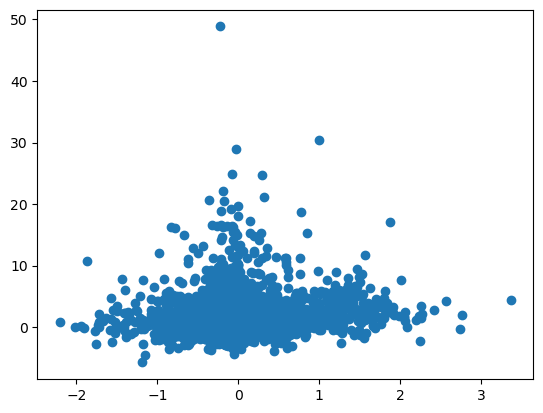

In [29]:
plt.scatter(a, foldx['total'])

In [27]:
a = raw_input.iloc[::2]['energy'].reset_index(drop=True) - raw_input.iloc[1::2]['energy'].reset_index(drop=True)

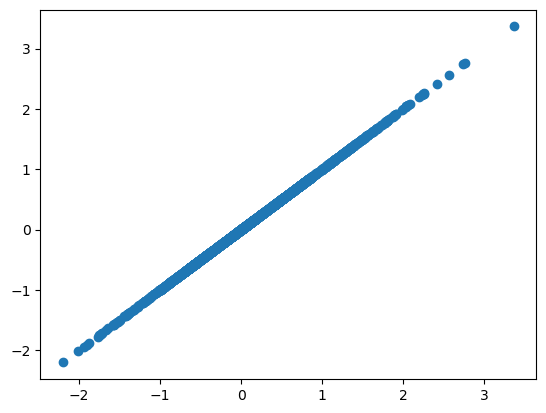

In [28]:
plt.scatter(a, foldx['energy'])

In [18]:
raw_input['total']

0        182.213
1        182.236
2        182.335
3        182.198
4        182.328
          ...   
11165    182.736
11166    180.532
11167    181.126
11168    180.683
11169    181.196
Name: total, Length: 11170, dtype: float64

In [6]:
len(run_list)

6

In [7]:
# run_list = []
# os.system(f"mkdir -p {pre}/logs/")
# for i, fileName in enumerate(fileList):
#     os.system(f"mkdir -p {pre}/foldx_results/batch_{i}/")
#     d = pd.read_csv(fileName)
#     print(i, fileName, len(d))
#     try:
#         pdbFile = d['pdb_file'].iloc[0]
#         assert len(set(d['pdb_file'])) == 1
#         mutantFile_cmd = get_mutantFile_cmd(d)
#         d['foldx_mut'] = mutantFile_cmd
#         one_mut = d.query("foldx_mut != ''").iloc[0]['foldx_mut']
#         d['foldx_mut'] = d['foldx_mut'].apply(lambda x: mutation_to_itself(one_mut) if x=='' else x)
#         mutantFile_cmd = ";\n".join(d['foldx_mut']) + ";"


#         with open(f"{pre}/foldx_results/batch_{i}/individual_list.txt", "w") as f:
#             f.write(mutantFile_cmd)

#         logFile = f"{pre}/logs/batch_{i}.log"
#         run_script_on_server(pre, i, pdbFile, logFile)
#     except Exception as e:
#         print(e)
#         continue
#     run_list.append(i)

# with open(f"{pre}/run.sh", "w") as f:
#     for i in run_list:
#         f.write(f"sbatch slurm_scripts/{i}.slurm\n")

In [94]:
i = 0

data = pd.read_csv("/home/luw//DMS/Binding_substitutions_DMS/CR6261_FluAH1_logKd_3GBN.csv")
d = data.reset_index(drop=True)


In [ ]:
    os.system(f"sbatch {pre}/slurm_scripts/{i}.slurm")

In [1]:
os.chdir(pre)
input_ = []
for pdb, group in new_data.groupby("pdb"):
    # print(pdb)
    if os.path.exists(f"{pdbSource}/{pdb}.pdb"):
        x = pre, pdb, group, pdbSource
        input_.append(x)
        
